# Notebook 1: Data Exploration, Cleaning and Feature Engineering
**Assignment 1 – Predicting Breast Cancer with Decision Trees and Random Forests**

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository (dataset ID 17).
**Goal:** Predict whether a breast mass is *malignant* or *benign* from measurements of cell nuclei computed from a digitized image of a fine needle aspirate (FNA).

**Contents of this notebook**
1. Setup and loading the data
2. Initial exploration
3. Summary statistics
4. Visualizations (target, feature distributions, outliers, correlations)
5. Preprocessing (missing values, duplicates, target encoding)
6. Feature engineering / selection (correlation filtering, mutual information)
7. Train/test split and scaling
8. Saving processed data for Notebook 2

## 1. Setup and Loading the Data

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed so results are reproducible
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
PALETTE = {"B": "#4C9F70", "M": "#D9534F"}   # Benign = green, Malignant = red

# Folders for figures and processed data
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

The raw UCI file `wdbc.data` has **no header row**. Each tumour has 10 base measurements of the cell nuclei, each reported
as the **mean**, **standard error (se)** and **worst** (mean of the three largest values), giving 30 features plus an ID and the diagnosis.

In [2]:
base_features = ["radius", "texture", "perimeter", "area", "smoothness",
                 "compactness", "concavity", "concave_points",
                 "symmetry", "fractal_dimension"]

columns = (["id", "diagnosis"]
           + [f"{f}_mean" for f in base_features]
           + [f"{f}_se" for f in base_features]
           + [f"{f}_worst" for f in base_features])

RAW_PATH = "data/raw/wdbc.data"
if os.path.exists(RAW_PATH):
    df = pd.read_csv(RAW_PATH, header=None, names=columns)
    print("Loaded dataset from UCI file:", RAW_PATH)
else:
    # Fallback: scikit-learn ships an identical copy of the same UCI dataset
    from sklearn.datasets import load_breast_cancer
    bc = load_breast_cancer()
    df = pd.DataFrame(bc.data, columns=columns[2:])
    df.insert(0, "diagnosis", np.where(bc.target == 0, "M", "B"))   # sklearn: 0 = malignant
    df.insert(0, "id", np.arange(len(df)))
    print("UCI file not found - loaded the identical copy bundled with scikit-learn")

df.head()

UCI file not found - loaded the identical copy bundled with scikit-learn


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Initial Exploration

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types and non-null counts:")
df.info()

Shape (rows, columns): (569, 32)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se    

In [4]:
# Data quality checks
print("Total missing values      :", df.isnull().sum().sum())
print("Duplicate rows            :", df.duplicated().sum())
print("Duplicate patient IDs     :", df["id"].duplicated().sum())
print("Unique diagnosis labels   :", df["diagnosis"].unique())

Total missing values      : 0
Duplicate rows            : 0
Duplicate patient IDs     : 0
Unique diagnosis labels   : ['M' 'B']


In [5]:
# Class balance of the target variable
counts = df["diagnosis"].value_counts()
summary = pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(2)})
summary.index = summary.index.map({"B": "B (Benign)", "M": "M (Malignant)"})
summary

,count,percent
diagnosis,,
B (Benign),357,62.74
M (Malignant),212,37.26


**Observations**
- The dataset has **569 patients** and **30 numeric features**, with no missing values.
- The target is moderately imbalanced (about 63% benign / 37% malignant). Accuracy alone can therefore be misleading, so we will also use
  precision, recall, F1 and ROC-AUC. In a cancer-screening setting, **recall for the malignant class** (not missing a cancer) is especially important.

## 3. Summary Statistics

In [6]:
df.drop(columns=['id']).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
concave_points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


In [7]:
# Statistics split by diagnosis: how do the class means differ for the 'mean' features?
mean_cols = [c for c in df.columns if c.endswith("_mean")]
df.groupby("diagnosis")[mean_cols].mean().T.round(3)

diagnosis,B,M
radius_mean,12.147,17.463
texture_mean,17.915,21.605
perimeter_mean,78.075,115.365
area_mean,462.790,978.376
smoothness_mean,0.092,0.103
compactness_mean,0.080,0.145
concavity_mean,0.046,0.161
concave_points_mean,0.026,0.088
symmetry_mean,0.174,0.193
fractal_dimension_mean,0.063,0.063


In [8]:
# Skewness of each feature (|skew| > 1 indicates a strongly skewed distribution)
skew = df.drop(columns=["id", "diagnosis"]).skew().sort_values(ascending=False)
skew.head(10).round(2)

area_se                    5.45
concavity_se               5.11
fractal_dimension_se       3.92
perimeter_se               3.44
radius_se                  3.09
smoothness_se              2.31
symmetry_se                2.20
compactness_se             1.90
area_worst                 1.86
fractal_dimension_worst    1.66
dtype: float64

## 4. Visualizations

### 4.1 Target variable

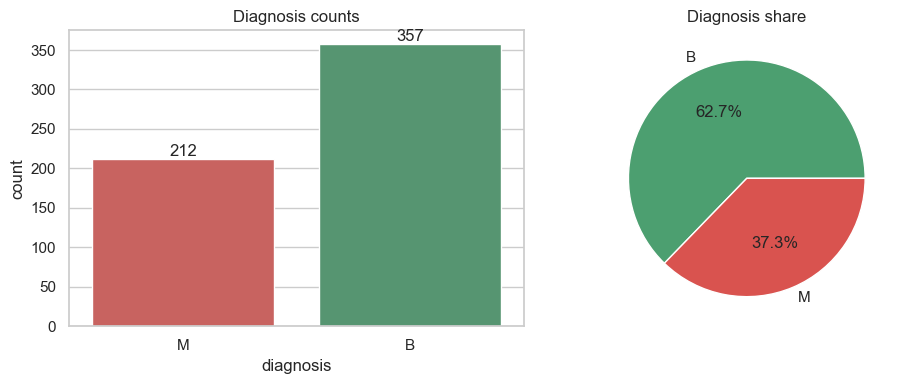

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette=PALETTE, legend=False, ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set_title("Diagnosis counts")
df["diagnosis"].value_counts().plot.pie(autopct="%1.1f%%", colors=[PALETTE["B"], PALETTE["M"]],
                                         ax=axes[1], ylabel="")
axes[1].set_title("Diagnosis share")
plt.tight_layout()
plt.savefig("outputs/figures/01_target_distribution.png", dpi=150)
plt.show()

### 4.2 Feature distributions by diagnosis

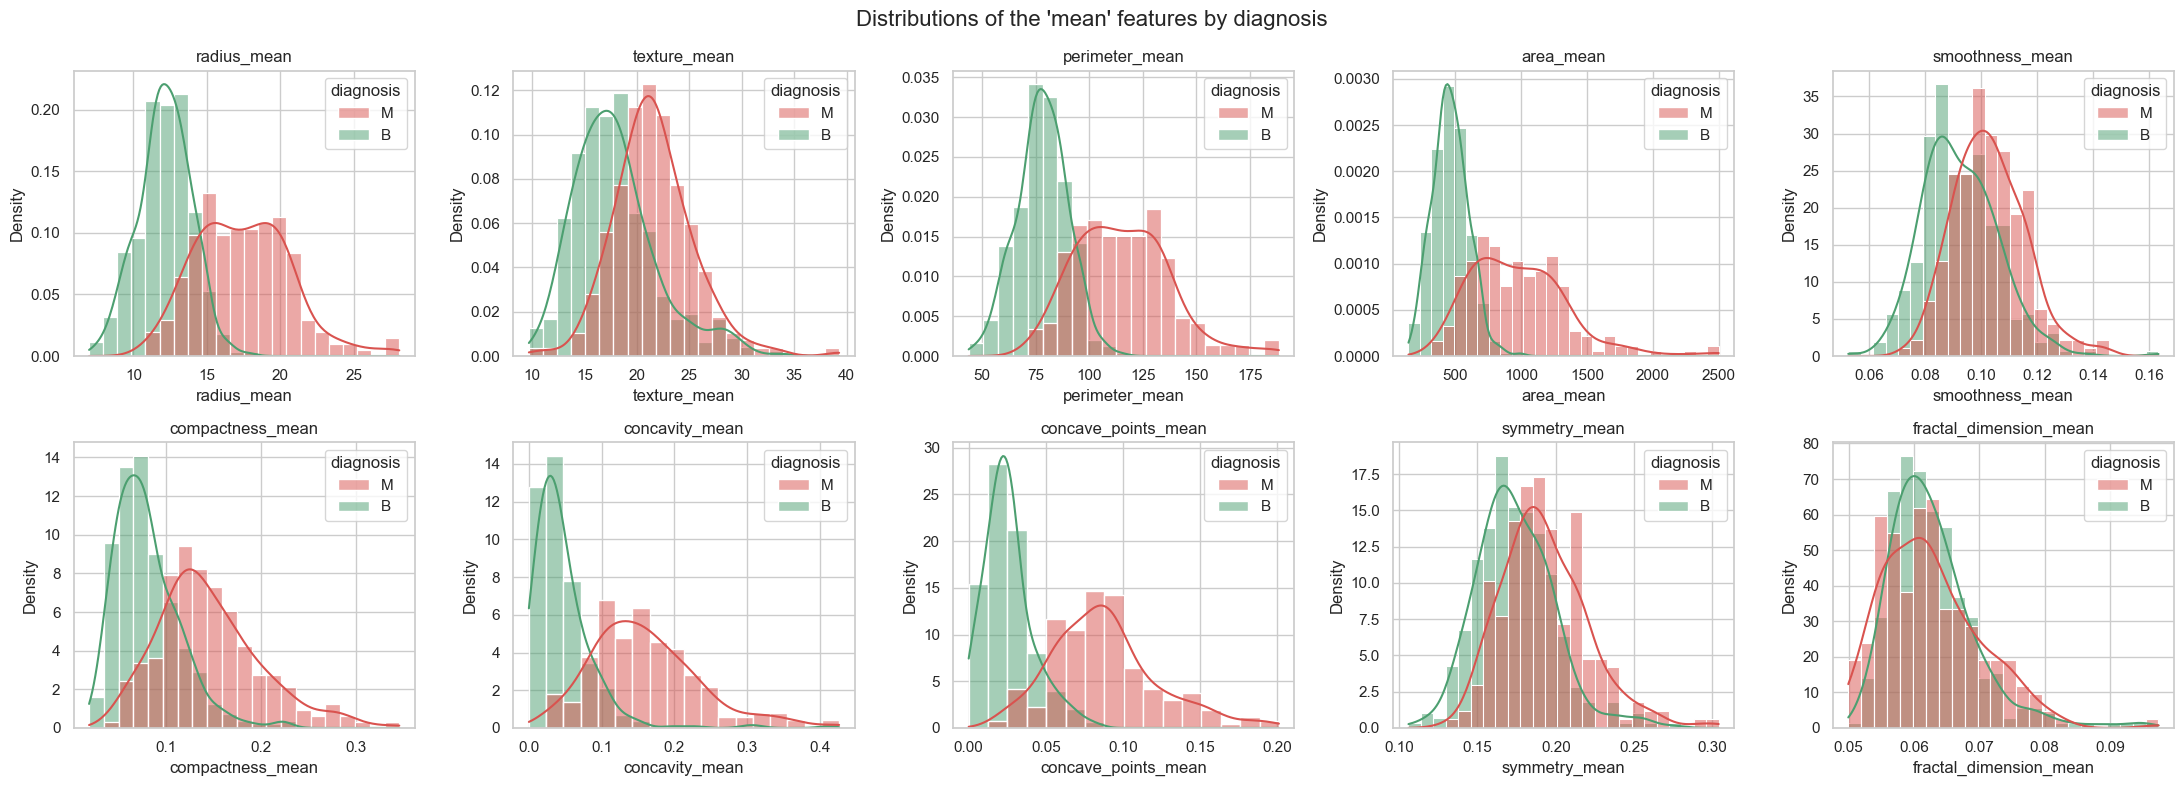

In [10]:
def plot_distributions(cols, title, fname):
    fig, axes = plt.subplots(2, 5, figsize=(22, 8))
    for ax, col in zip(axes.ravel(), cols):
        sns.histplot(data=df, x=col, hue="diagnosis", kde=True, palette=PALETTE, ax=ax, stat="density", common_norm=False)
        ax.set_title(col)
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(f"outputs/figures/{fname}", dpi=150)
    plt.show()

plot_distributions([c for c in df.columns if c.endswith("_mean")],
                   "Distributions of the 'mean' features by diagnosis", "02a_distributions_mean.png")

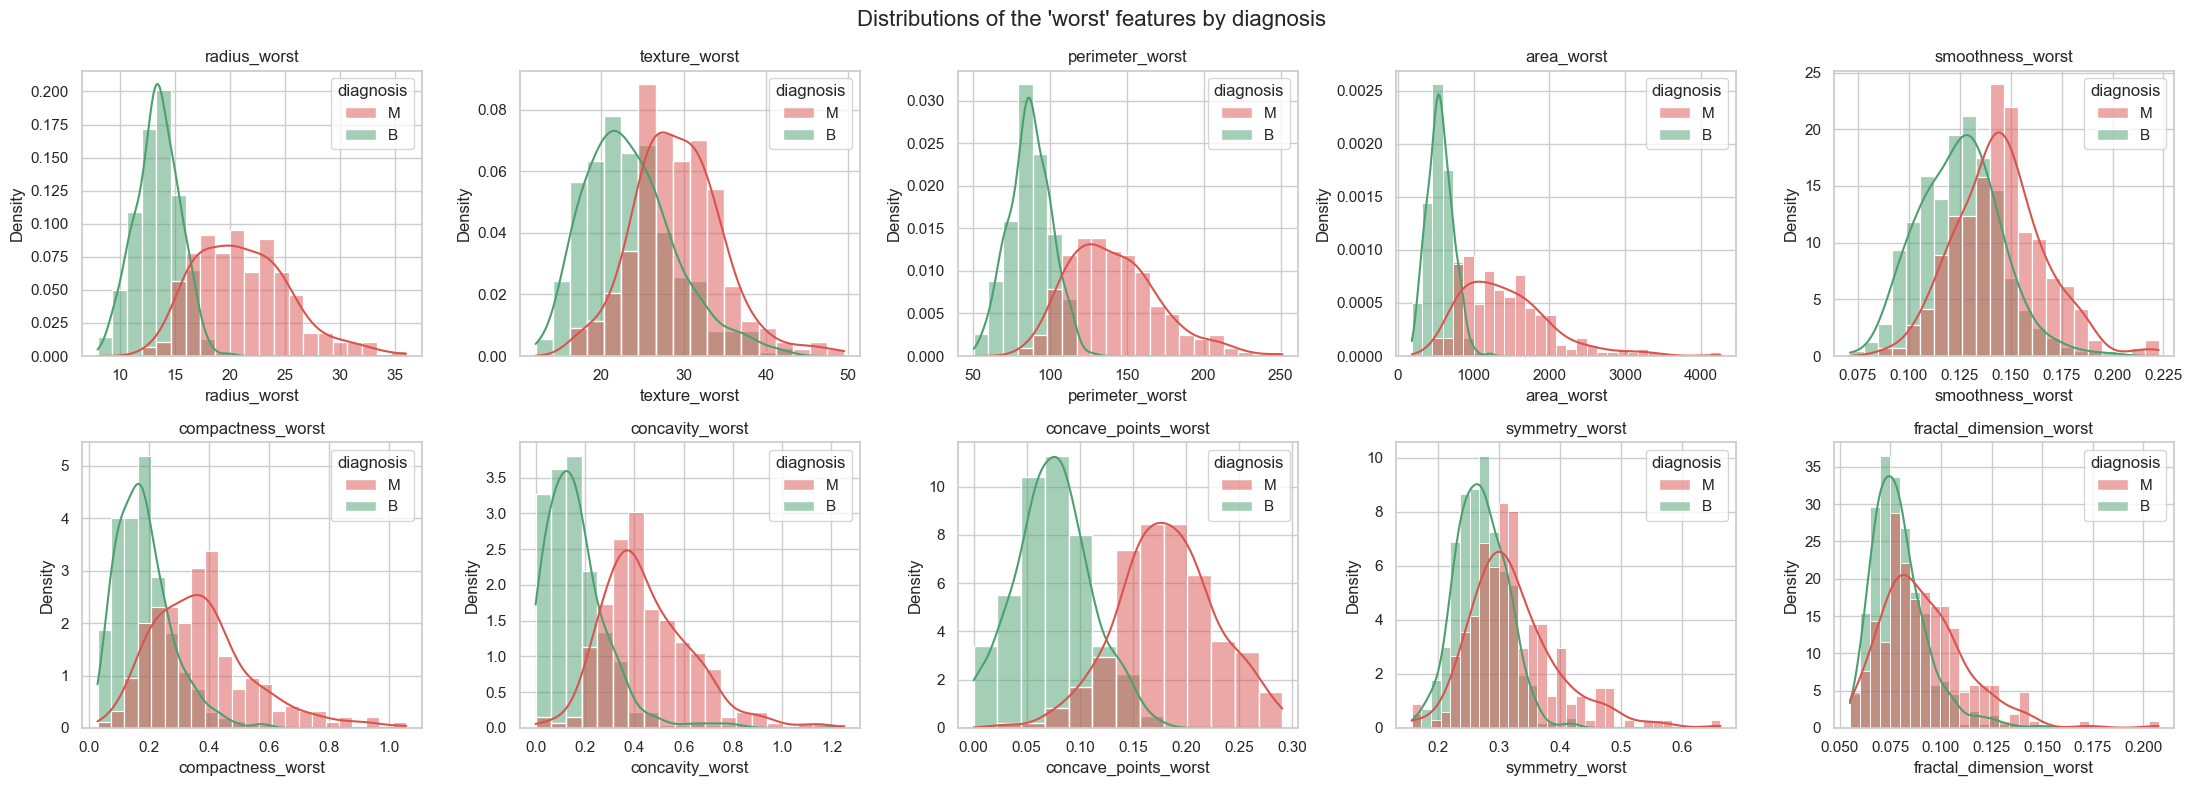

In [11]:
plot_distributions([c for c in df.columns if c.endswith("_worst")],
                   "Distributions of the 'worst' features by diagnosis", "02b_distributions_worst.png")

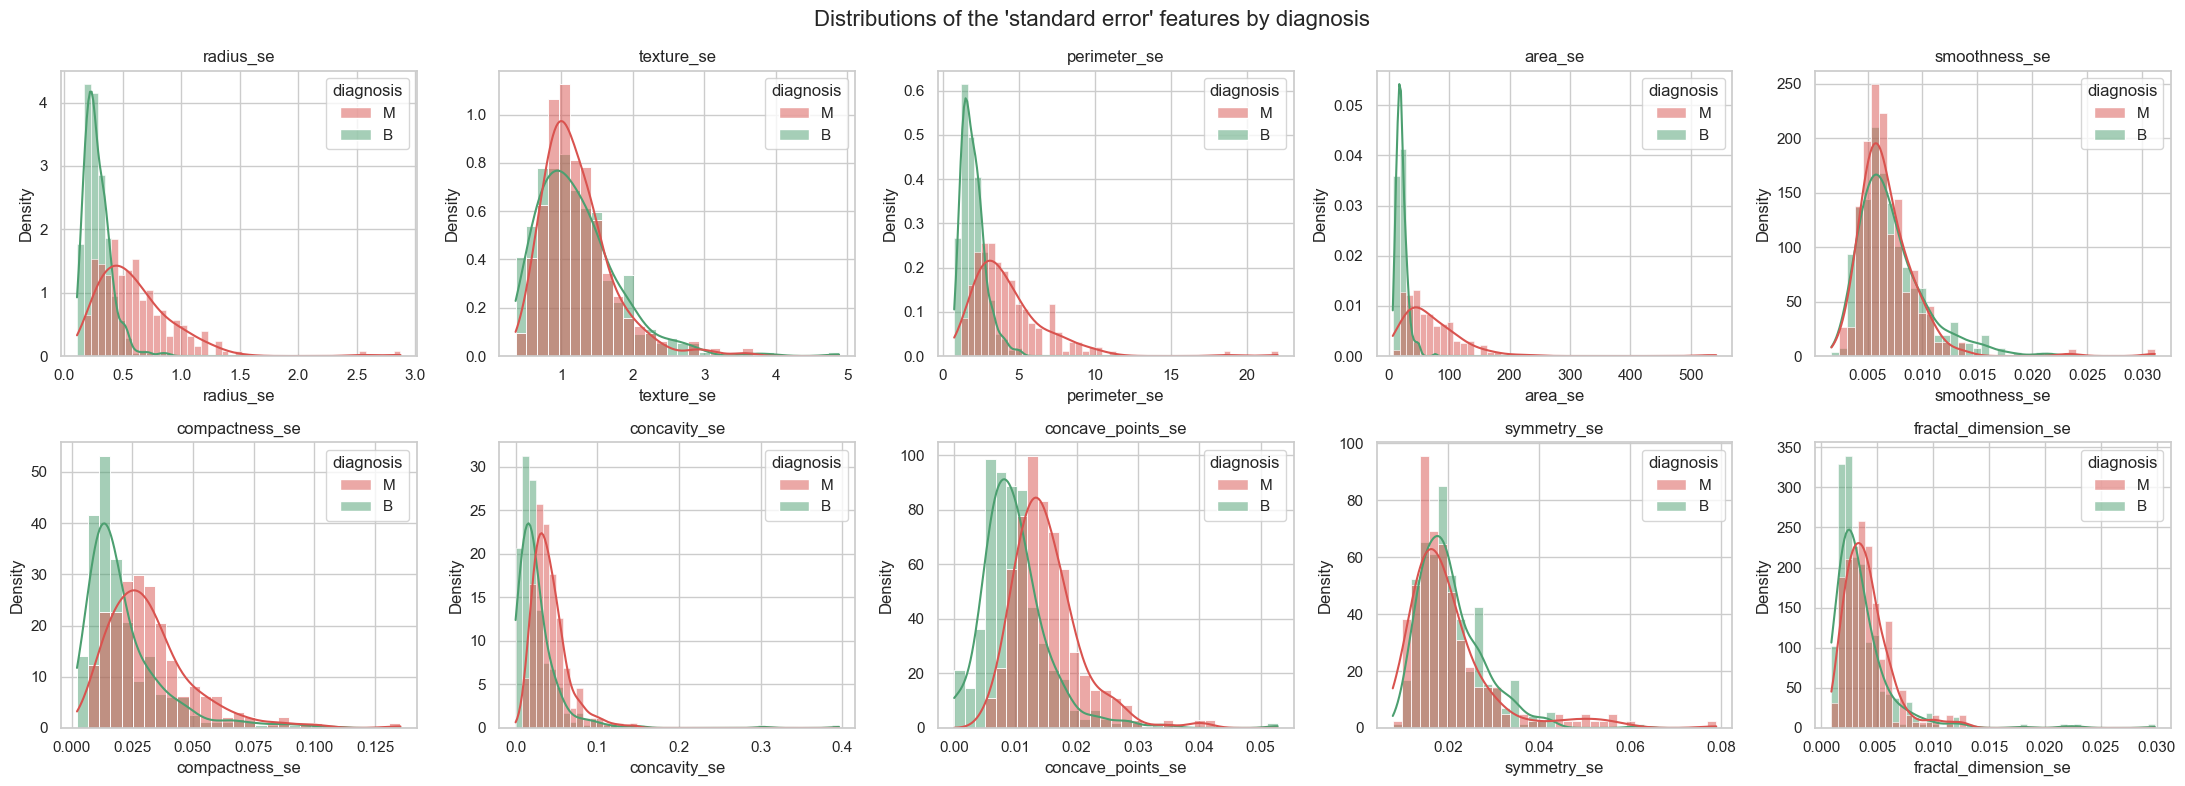

In [12]:
plot_distributions([c for c in df.columns if c.endswith("_se")],
                   "Distributions of the 'standard error' features by diagnosis", "02c_distributions_se.png")

**Observation:** For size-related features (radius, perimeter, area, concavity, concave points) the malignant distribution is clearly shifted to the right,
meaning these features separate the two classes well. Features such as `fractal_dimension_mean` and `symmetry_se` overlap heavily and are weaker predictors.

### 4.3 Boxplots (class separation and outliers)

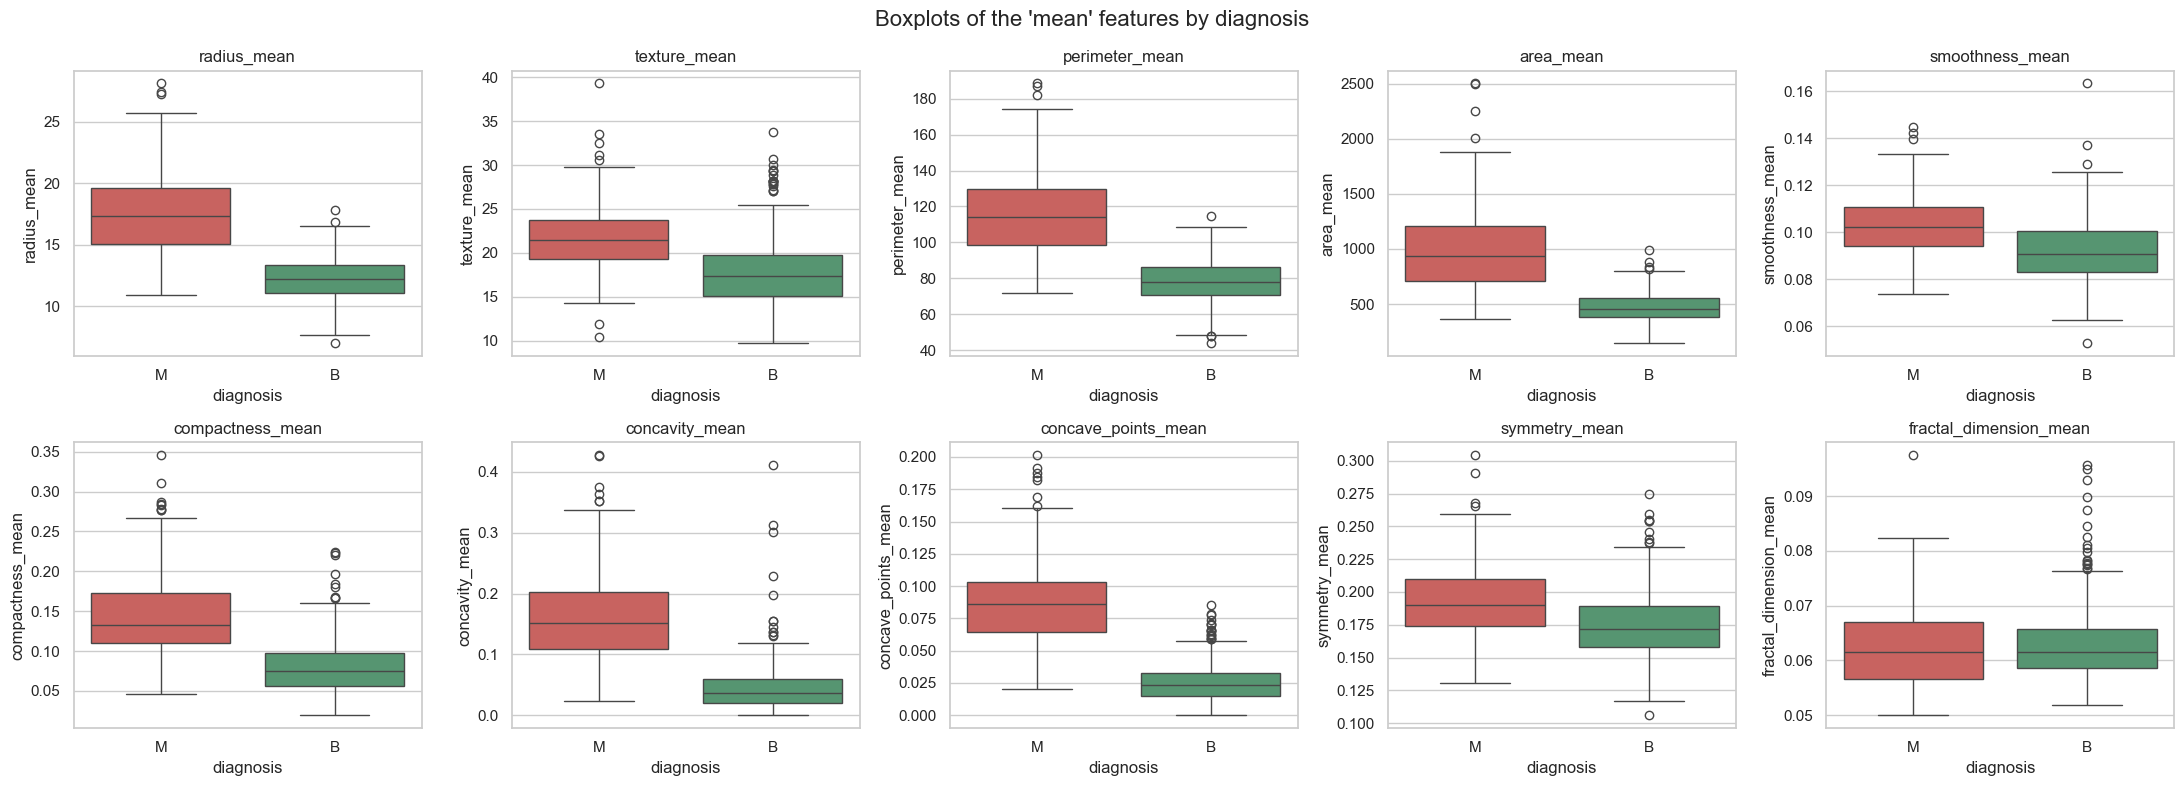

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, col in zip(axes.ravel(), [c for c in df.columns if c.endswith("_mean")]):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis", palette=PALETTE, legend=False, ax=ax)
    ax.set_title(col)
plt.suptitle("Boxplots of the 'mean' features by diagnosis", fontsize=16)
plt.tight_layout()
plt.savefig("outputs/figures/03_boxplots_mean.png", dpi=150)
plt.show()

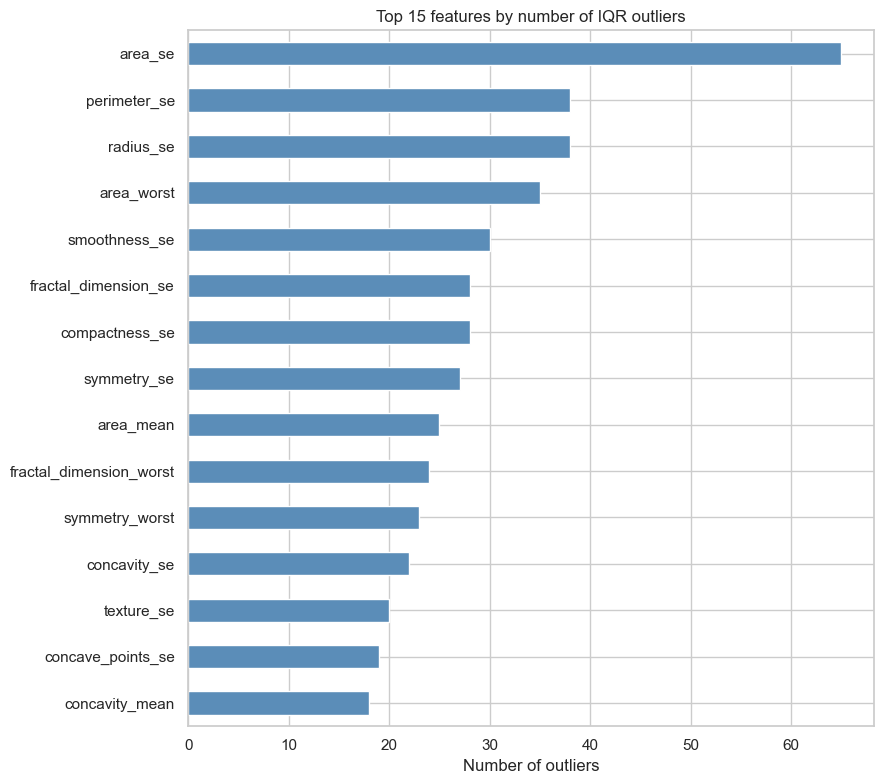

Rows containing at least one outlier: 171


In [14]:
# Outlier count per feature using the 1.5 x IQR rule
X_all = df.drop(columns=["id", "diagnosis"])
Q1, Q3 = X_all.quantile(0.25), X_all.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X_all < Q1 - 1.5 * IQR) | (X_all > Q3 + 1.5 * IQR)).sum().sort_values(ascending=False)

plt.figure(figsize=(9, 8))
outliers.head(15).sort_values().plot.barh(color="#5B8DB8")
plt.title("Top 15 features by number of IQR outliers")
plt.xlabel("Number of outliers")
plt.tight_layout()
plt.savefig("outputs/figures/04_outlier_counts.png", dpi=150)
plt.show()
print("Rows containing at least one outlier:", ((X_all < Q1 - 1.5*IQR) | (X_all > Q3 + 1.5*IQR)).any(axis=1).sum())

**Decision on outliers:** The outliers are mostly large malignant tumours (genuine clinical values, not data-entry errors), so they are **kept**.
Decision trees and random forests split on thresholds, which makes them robust to extreme values.

### 4.4 Correlations

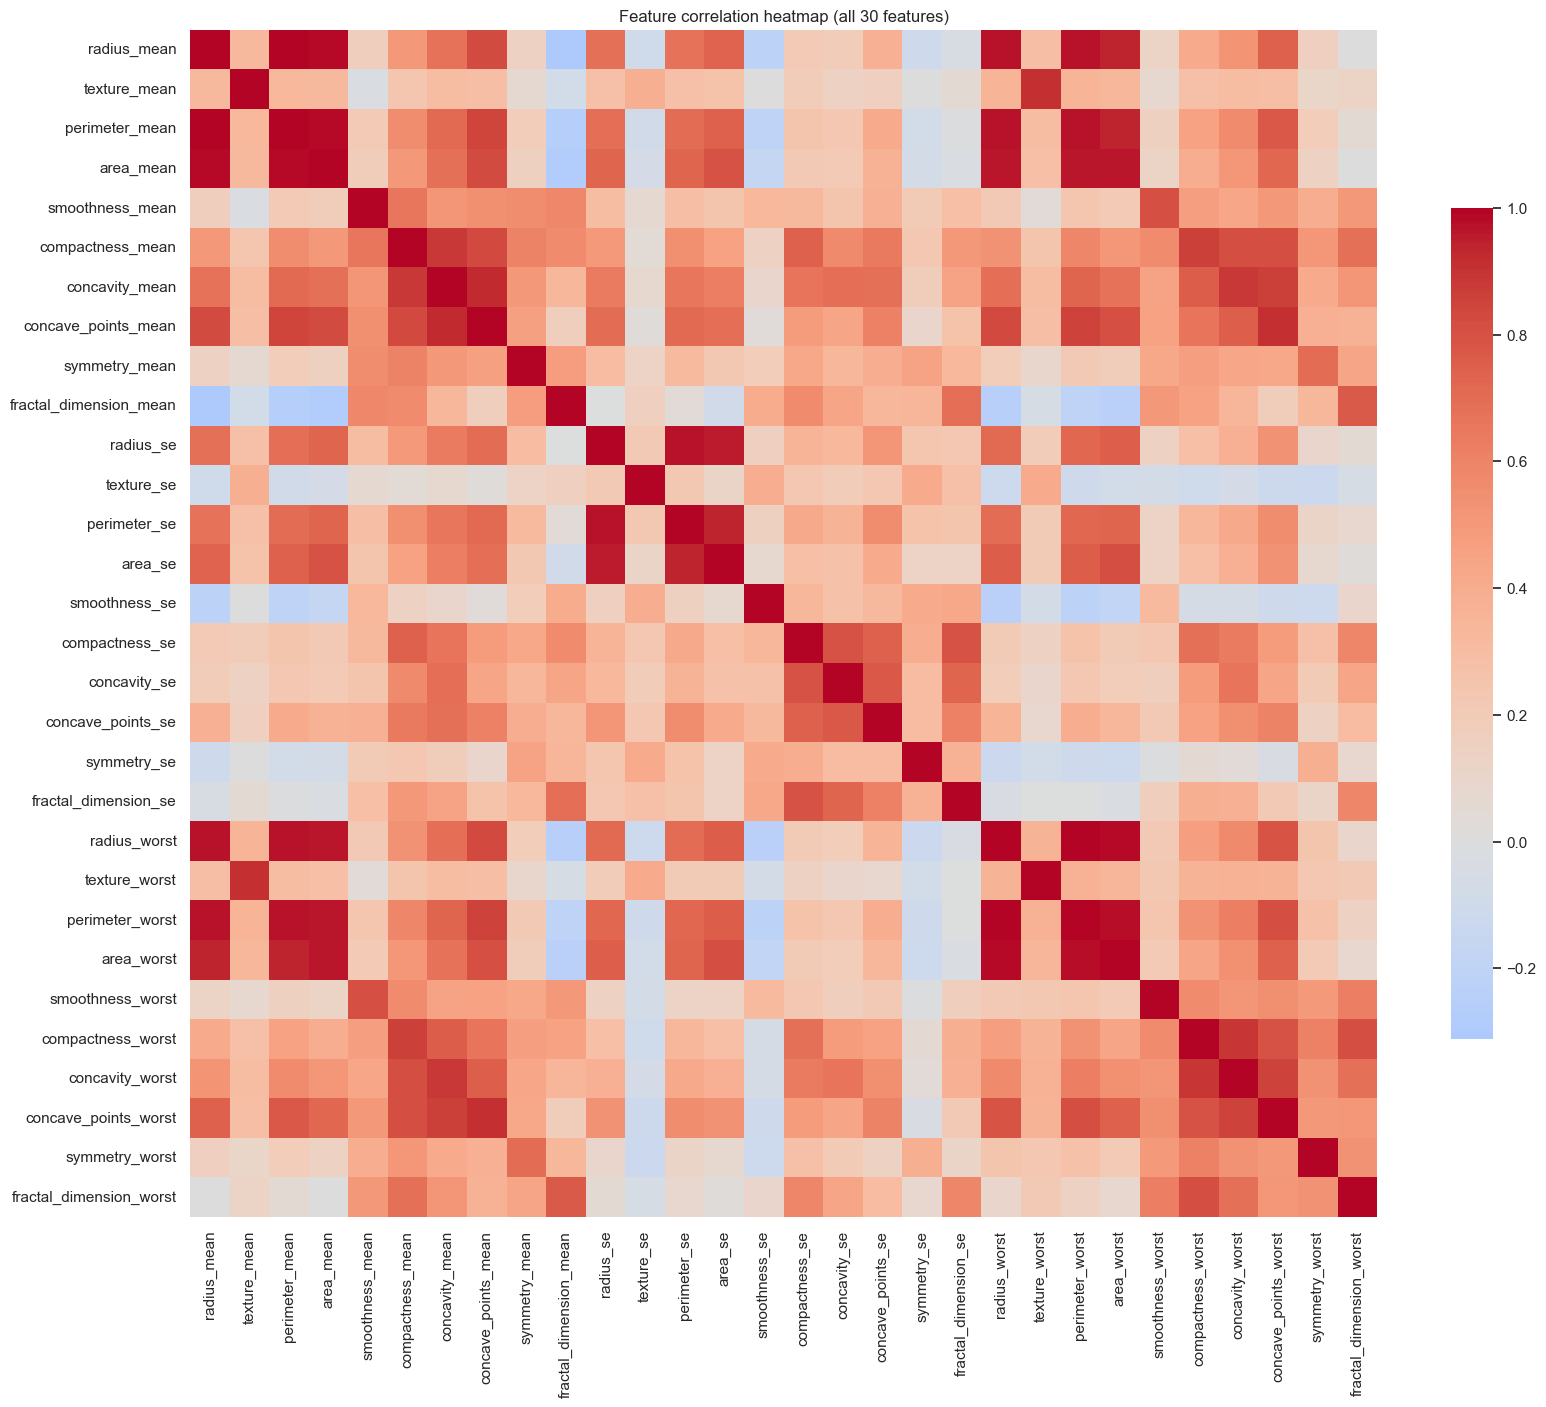

In [15]:
corr = X_all.corr()
plt.figure(figsize=(17, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7})
plt.title("Feature correlation heatmap (all 30 features)")
plt.tight_layout()
plt.savefig("outputs/figures/05_correlation_heatmap.png", dpi=150)
plt.show()

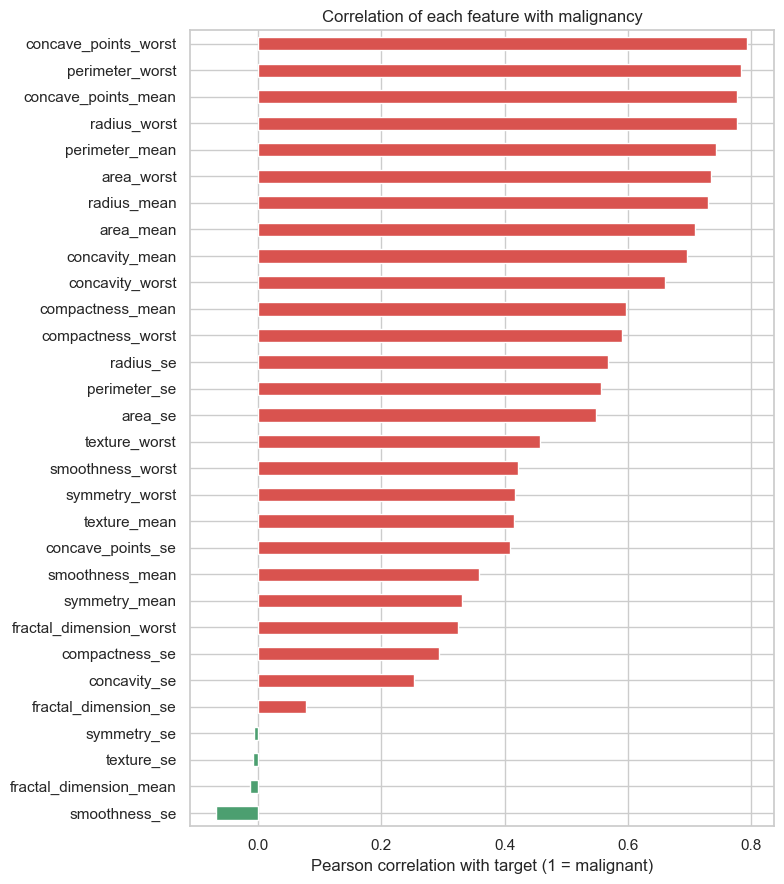

perimeter_mean          0.743
radius_worst            0.776
concave_points_mean     0.777
perimeter_worst         0.783
concave_points_worst    0.794
dtype: float64

In [16]:
# Correlation of each feature with the (numerically encoded) target
target_num = (df["diagnosis"] == "M").astype(int)
corr_target = X_all.corrwith(target_num).sort_values()

plt.figure(figsize=(8, 9))
corr_target.plot.barh(color=["#4C9F70" if v < 0 else "#D9534F" for v in corr_target])
plt.title("Correlation of each feature with malignancy")
plt.xlabel("Pearson correlation with target (1 = malignant)")
plt.tight_layout()
plt.savefig("outputs/figures/06_correlation_with_target.png", dpi=150)
plt.show()
corr_target.tail(5).round(3)

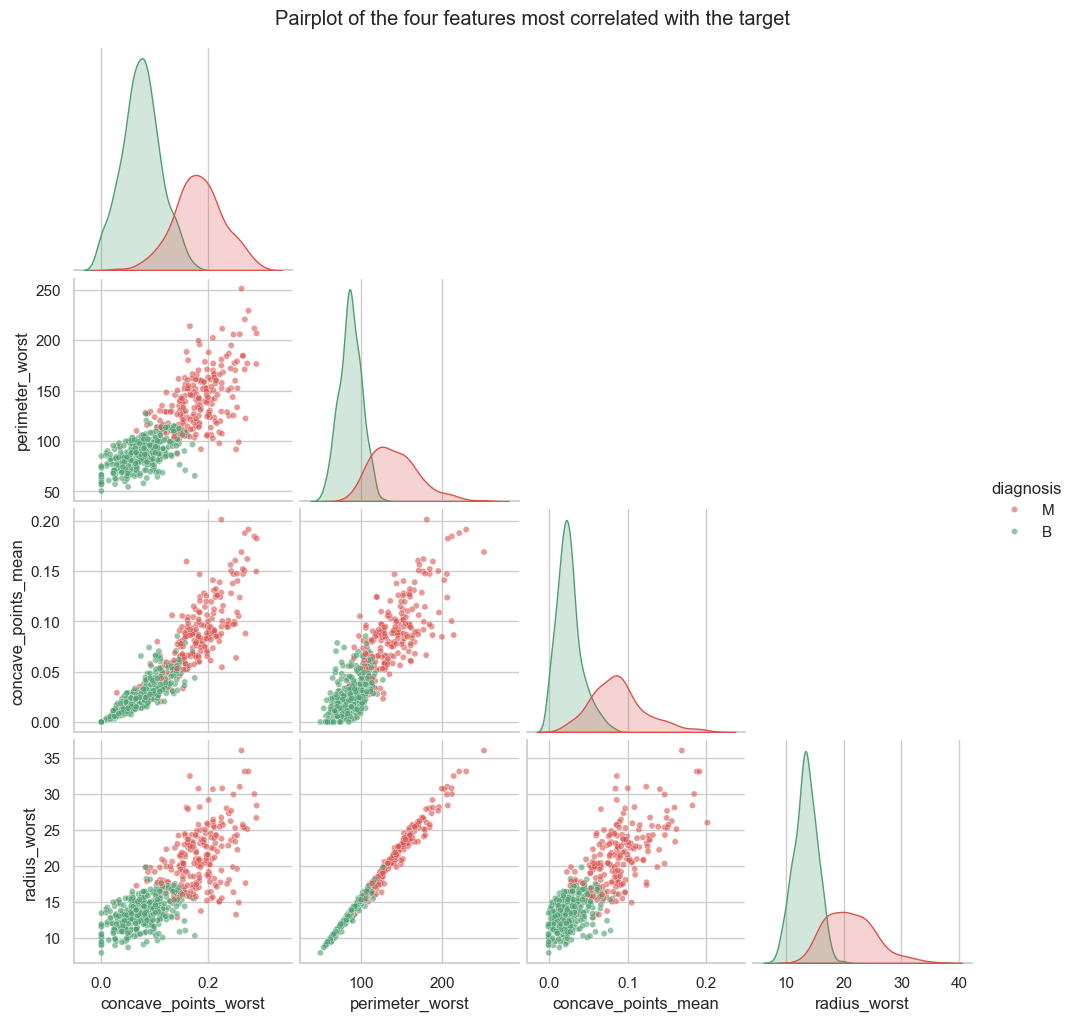

In [17]:
# Pairplot of the most informative features
top4 = corr_target.abs().sort_values(ascending=False).head(4).index.tolist()
g = sns.pairplot(df[top4 + ["diagnosis"]], hue="diagnosis", palette=PALETTE, corner=True, plot_kws={"alpha": 0.6, "s": 20})
g.fig.suptitle("Pairplot of the four features most correlated with the target", y=1.02)
g.savefig("outputs/figures/07_pairplot_top_features.png", dpi=150)
plt.show()

**Observation:** Many features are very highly correlated (e.g. radius, perimeter and area are almost perfectly correlated because they all measure tumour size).
This **multicollinearity** does not hurt tree accuracy, but it splits importance across duplicate features and makes interpretation harder, which motivates feature selection in Section 6.

## 5. Preprocessing and Cleaning

In [18]:
df_clean = df.copy()

# 1. Missing values - none found, but we verify and would impute with the median if any appeared
n_missing = df_clean.isnull().sum().sum()
print("Missing values:", n_missing)
if n_missing > 0:
    num_cols = df_clean.select_dtypes("number").columns
    df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())

# 2. Duplicates
n_dup = df_clean.duplicated(subset=[c for c in df_clean.columns if c != "id"]).sum()
print("Duplicate records (ignoring ID):", n_dup)
df_clean = df_clean.drop_duplicates(subset=[c for c in df_clean.columns if c != "id"])

# 3. Encode the target: Malignant = 1 (positive class), Benign = 0
df_clean["target"] = (df_clean["diagnosis"] == "M").astype(int)

# 4. Drop the identifier (no predictive meaning) and the text label
df_clean = df_clean.drop(columns=["id", "diagnosis"])

# 5. Sanity check on value ranges (all measurements must be non-negative)
print("Negative values present:", (df_clean.drop(columns="target") < 0).any().any())
print("Clean dataset shape:", df_clean.shape)

Missing values: 0
Duplicate records (ignoring ID): 0
Negative values present: False
Clean dataset shape: (569, 31)


## 6. Feature Engineering and Feature Selection

Two steps are applied:
1. **Correlation filter** – among pairs of features with |r| > 0.90, drop one of the pair (keeping the one that is more correlated with the target). This removes redundancy.
2. **Mutual information ranking** – measures how much information each remaining feature gives about the diagnosis. Used to confirm the selected features are informative.

In [19]:
features = df_clean.drop(columns="target")
y = df_clean["target"]
corr_abs = features.corr().abs()
target_corr = features.corrwith(y).abs()

THRESHOLD = 0.90
to_drop = set()
cols = list(features.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        a, b = cols[i], cols[j]
        if a in to_drop or b in to_drop:
            continue
        if corr_abs.loc[a, b] > THRESHOLD:
            # drop whichever is less related to the target
            to_drop.add(a if target_corr[a] < target_corr[b] else b)

selected_features = [c for c in cols if c not in to_drop]
print(f"Original features : {len(cols)}")
print(f"Dropped (|r|>{THRESHOLD}) : {len(to_drop)}")
print(f"Selected features : {len(selected_features)}\n")
print("Dropped:", sorted(to_drop))
print("\nKept   :", selected_features)

Original features : 30
Dropped (|r|>0.9) : 10
Selected features : 20

Dropped: ['area_mean', 'area_se', 'area_worst', 'concave_points_mean', 'concavity_mean', 'perimeter_mean', 'perimeter_se', 'radius_mean', 'radius_worst', 'texture_mean']

Kept   : ['smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'texture_worst', 'perimeter_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


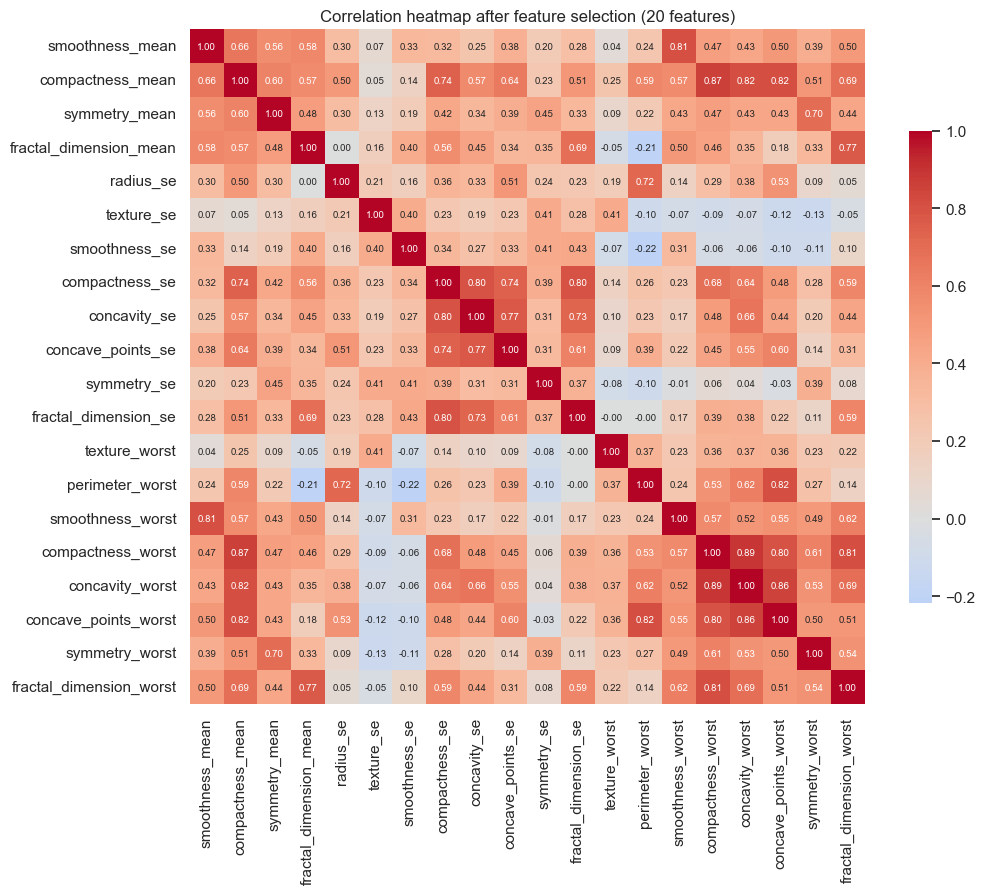

In [20]:
# Heatmap after feature selection
plt.figure(figsize=(11, 9))
sns.heatmap(features[selected_features].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, square=True, cbar_kws={"shrink": 0.7})
plt.title(f"Correlation heatmap after feature selection ({len(selected_features)} features)")
plt.tight_layout()
plt.savefig("outputs/figures/08_correlation_after_selection.png", dpi=150)
plt.show()

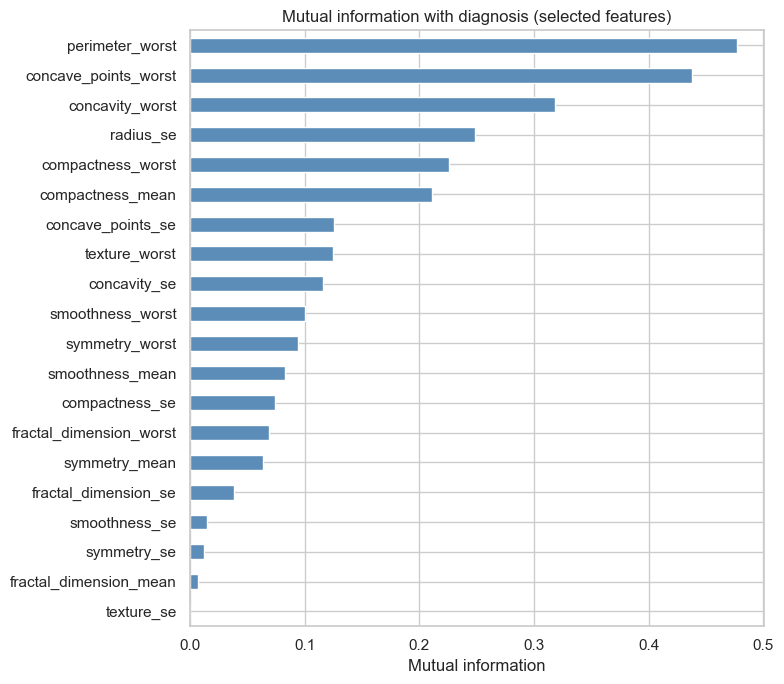

perimeter_worst         0.477
concave_points_worst    0.437
concavity_worst         0.318
radius_se               0.249
compactness_worst       0.226
dtype: float64

In [21]:
# Mutual information of the selected features with the target
mi = pd.Series(mutual_info_classif(features[selected_features], y, random_state=RANDOM_STATE),
               index=selected_features).sort_values()
plt.figure(figsize=(8, 7))
mi.plot.barh(color="#5B8DB8")
plt.title("Mutual information with diagnosis (selected features)")
plt.xlabel("Mutual information")
plt.tight_layout()
plt.savefig("outputs/figures/09_mutual_information.png", dpi=150)
plt.show()
mi.sort_values(ascending=False).head(5).round(3)

**Why select features?** Trees can handle correlated inputs, but removing near-duplicates (a) makes the tree and the feature-importance charts easier to interpret,
(b) reduces the chance that importance is arbitrarily split between redundant features, and (c) gives a simpler, faster model.

## 7. Train/Test Split and Scaling

In [22]:
X = df_clean[selected_features]

# Stratified split keeps the benign/malignant ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nMalignant share - train: {:.1%}, test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train: (455, 20) | Test: (114, 20)

Malignant share - train: 37.4%, test: 36.8%


In [24]:
# Standardization: fit on TRAIN only, then apply to test (prevents data leakage)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=selected_features, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=selected_features, index=X_test.index)

print("Scaled train mean (approx 0):", round(float(X_train_scaled.mean().abs().max()), 6))
print("Scaled train std  (approx 1):", round(float(X_train_scaled.std().mean()), 3))

Scaled train mean (approx 0): 0.0
Scaled train std  (approx 1): 1.001


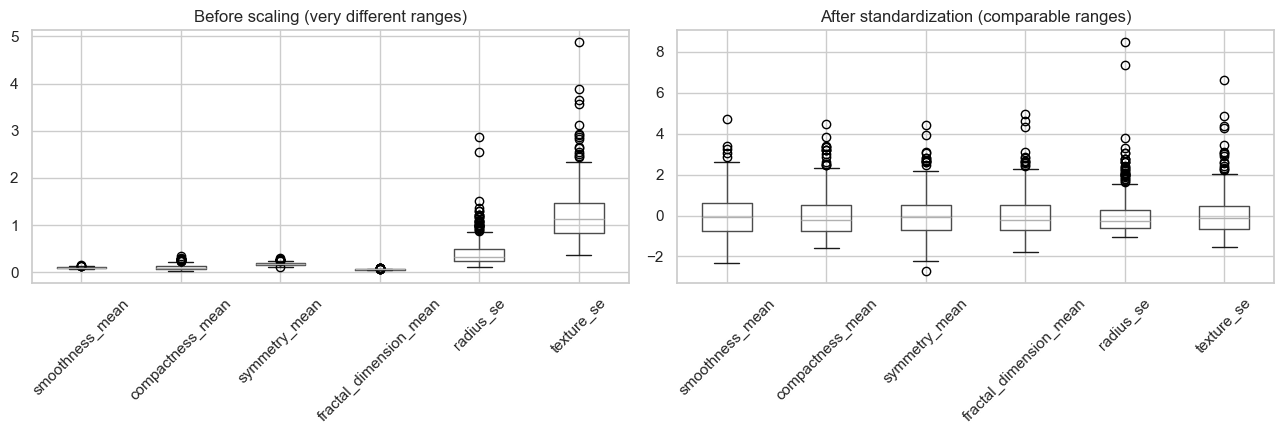

In [25]:
# Before / after scaling comparison for three features
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
X_train[selected_features[:6]].boxplot(ax=axes[0]); axes[0].set_title("Before scaling (very different ranges)")
X_train_scaled[selected_features[:6]].boxplot(ax=axes[1]); axes[1].set_title("After standardization (comparable ranges)")
for ax in axes: ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("outputs/figures/10_scaling_before_after.png", dpi=150)
plt.show()

**Note on scaling:** Decision trees and random forests are *scale-invariant* (they only compare a feature to a threshold), so scaling will not change their predictions.
We still standardize, as required by the brief, and Notebook 2 verifies this empirically. The unscaled data is kept for the tree diagram so thresholds stay in real measurement units.

## 8. Save Processed Data for Notebook 2

In [26]:
X_train.to_csv("data/processed/X_train.csv", index=False)
X_test.to_csv("data/processed/X_test.csv", index=False)
X_train_scaled.to_csv("data/processed/X_train_scaled.csv", index=False)
X_test_scaled.to_csv("data/processed/X_test_scaled.csv", index=False)
y_train.to_csv("data/processed/y_train.csv", index=False)
y_test.to_csv("data/processed/y_test.csv", index=False)
df_clean.to_csv("data/processed/cleaned_full.csv", index=False)
with open("data/processed/selected_features.json", "w") as f:
    json.dump(selected_features, f)

print("Saved files:", sorted(os.listdir("data/processed")))

Saved files: ['X_test.csv', 'X_test_scaled.csv', 'X_train.csv', 'X_train_scaled.csv', 'cleaned_full.csv', 'selected_features.json', 'y_test.csv', 'y_train.csv']


## Summary of Notebook 1
| Step | Result |
|---|---|
| Records / features | 569 patients, 30 numeric features |
| Missing values / duplicates | None found |
| Target | Malignant = 1, Benign = 0 (~37% / 63%) |
| Outliers | Retained (valid clinical values, trees are robust) |
| Feature selection | Correlation filter (|r| > 0.90) removed redundant features; mutual information confirms informativeness |
| Split | 80/20 stratified, random_state = 42 |
| Scaling | StandardScaler fitted on training data only |

**Next:** open `02_modelling_evaluation.ipynb` to build the Decision Tree and Random Forest.